In [2]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns

In [4]:
from sklearn.model_selection import train_test_split 
from sklearn.linear_model import LinearRegression, Ridge, Lasso 
from sklearn.metrics import mean_squared_error, r2_score

In [5]:
# 1. Load and Pre-process the Dataset
df = pd.read_csv('uber.csv') 

In [6]:
print("Initial Data Info:") 
print(df.info())

Initial Data Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  object 
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  object 
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), object(2)
memory usage: 13.7+ MB
None


In [7]:
print(df.head(5))

   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325                1  
2         -73.962565         40.772647                1  
3         

In [8]:
# Drop rows with missing values 
df = df.dropna()

In [9]:
# Convert datetime columns 
df['pickup_datetime'] = pd.to_datetime(df['pickup_datetime'])

In [10]:
# Feature Engineering: Extract hour, day, month 
df['hour'] = df['pickup_datetime'].dt.hour 
df['day'] = df['pickup_datetime'].dt.day 
df['month'] = df['pickup_datetime'].dt.month

In [12]:
# Remove unneeded columns 
df = df.drop(columns=['key', 'pickup_datetime'])

In [16]:
# Calculate distance (Haversine formula) 
def haversine(lat1, lon1, lat2, lon2):    
    R = 6371  # Earth radius in km    
    phi1, phi2 = np.radians(lat1), np.radians(lat2)    
    dphi = np.radians(lat2 - lat1)    
    dlambda = np.radians(lon2 - lon1)    
    a = np.sin(dphi/2)**2 + np.cos(phi1)*np.cos(phi2)*np.sin(dlambda/2)**2    
    return 2 * R * np.arcsin(np.sqrt(a)) 

df['distance_km'] = haversine(df['pickup_latitude'], df['pickup_longitude'],                              
                              df['dropoff_latitude'], df['dropoff_longitude'])

In [17]:
print(df[['distance_km']].head())


   distance_km
0     1.683323
1     2.457590
2     5.036377
3     1.661683
4     4.475450


In [18]:
df = df.drop(
    columns=[
        'pickup_latitude',
        'pickup_longitude',
        'dropoff_latitude',
        'dropoff_longitude'
    ]
)

print(df.head())

   Unnamed: 0  fare_amount  passenger_count  hour  day  month  distance_km
0    24238194          7.5                1    19    7      5     1.683323
1    27835199          7.7                1    20   17      7     2.457590
2    44984355         12.9                1    21   24      8     5.036377
3    25894730          5.3                3     8   26      6     1.661683
4    17610152         16.0                5    17   28      8     4.475450


In [19]:
df = df[
    (df['fare_amount'] > 0) &
    (df['passenger_count'].between(1, 6)) &
    (df['distance_km'] > 0) &
    (df['distance_km'] < 100) &
    (df['fare_amount'] < 500)
]

print("Dataset Shape After Removing Invalid Values:")
print(df.shape)

Dataset Shape After Removing Invalid Values:
(193192, 7)


In [22]:
from scipy.stats import zscore

z_scores = np.abs(
    zscore(df[['fare_amount', 'distance_km']])
)

df = df[(z_scores < 3).all(axis=1)]

print("Dataset Shape After Removing Outliers:")
print(df.shape)

Dataset Shape After Removing Outliers:
(186983, 7)


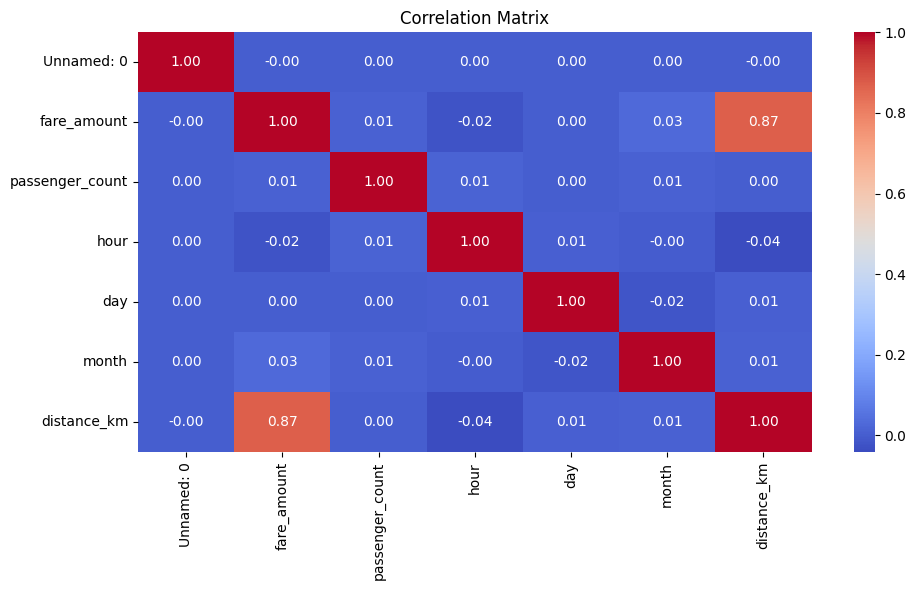

In [23]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

In [24]:
X = df.drop(columns=['fare_amount'])
y = df['fare_amount']

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Features:
   Unnamed: 0  passenger_count  hour  day  month  distance_km
0    24238194                1    19    7      5     1.683323
1    27835199                1    20   17      7     2.457590
2    44984355                1    21   24      8     5.036377
3    25894730                3     8   26      6     1.661683
4    17610152                5    17   28      8     4.475450

Target:
0     7.5
1     7.7
2    12.9
3     5.3
4    16.0
Name: fare_amount, dtype: float64


In [25]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (149586, 6)
Testing Data: (37397, 6)


In [26]:
lr = LinearRegression()

lr.fit(X_train, y_train)

y_pred_lr = lr.predict(X_test)

print("Linear Regression Model Trained Successfully!")

Linear Regression Model Trained Successfully!


In [27]:
ridge = Ridge(alpha=1.0)

ridge.fit(X_train, y_train)

y_pred_ridge = ridge.predict(X_test)

print("Ridge Regression Model Trained Successfully!")

Ridge Regression Model Trained Successfully!


In [28]:
lasso = Lasso(alpha=0.1, max_iter=10000)

lasso.fit(X_train, y_train)

y_pred_lasso = lasso.predict(X_test)

print("Lasso Regression Model Trained Successfully!")

Lasso Regression Model Trained Successfully!


In [29]:
def print_scores(model_name, y_true, y_pred):
    r2 = r2_score(y_true, y_pred)

    rmse = np.sqrt(
        mean_squared_error(y_true, y_pred)
    )

    print(f"\n{model_name}")
    print(f"R2 Score: {r2:.4f}")
    print(f"RMSE: {rmse:.4f}")


print_scores(
    "Linear Regression",
    y_test,
    y_pred_lr
)

print_scores(
    "Ridge Regression",
    y_test,
    y_pred_ridge
)

print_scores(
    "Lasso Regression",
    y_test,
    y_pred_lasso
)


Linear Regression
R2 Score: 0.7626
RMSE: 3.0385

Ridge Regression
R2 Score: 0.7626
RMSE: 3.0385

Lasso Regression
R2 Score: 0.7623
RMSE: 3.0404


In [30]:
results = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Ridge Regression',
        'Lasso Regression'
    ],
    'R2 Score': [
        r2_score(y_test, y_pred_lr),
        r2_score(y_test, y_pred_ridge),
        r2_score(y_test, y_pred_lasso)
    ],
    'RMSE': [
        np.sqrt(mean_squared_error(y_test, y_pred_lr)),
        np.sqrt(mean_squared_error(y_test, y_pred_ridge)),
        np.sqrt(mean_squared_error(y_test, y_pred_lasso))
    ]
})

print(results.to_string(index=False))

            Model  R2 Score     RMSE
Linear Regression  0.762593 3.038496
 Ridge Regression  0.762593 3.038496
 Lasso Regression  0.762293 3.040413


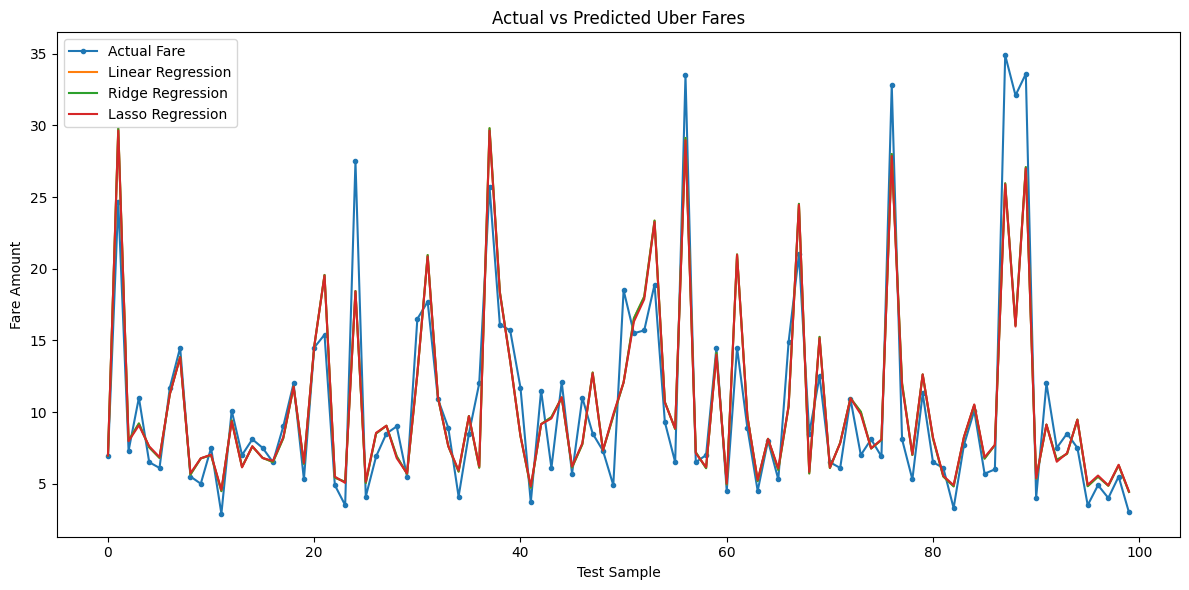

In [35]:
sample_size = min(100, len(y_test))

actual = y_test.iloc[:sample_size].to_numpy()

predicted_lr = y_pred_lr[:sample_size]
predicted_ridge = y_pred_ridge[:sample_size]
predicted_lasso = y_pred_lasso[:sample_size]

plt.figure(figsize=(12, 6))

plt.plot(actual, label='Actual Fare', marker='o', markersize=3)
plt.plot(predicted_lr, label='Linear Regression')
plt.plot(predicted_ridge, label='Ridge Regression')
plt.plot(predicted_lasso, label='Lasso Regression')

plt.title('Actual vs Predicted Uber Fares')
plt.xlabel('Test Sample')
plt.ylabel('Fare Amount')

plt.legend()
plt.tight_layout()
plt.show()

Actual Fare: 6.9
Predicted Fare: 6.95
